11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


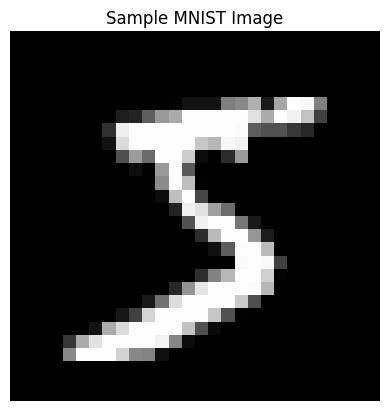

Label: 5
Training data shape: (60000, 784)
Testing data shape: (10000, 784)
Training labels shape: (60000, 10)
Testing labels shape: (10000, 10)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)


BEFORE TRAINING
----------------
Loss: 2.5507514476776123
Accuracy: 0.09740000218153

BEFORE TRAINING PREDICTION
--------------------------
Predicted Digit: 8
Actual Digit: 1


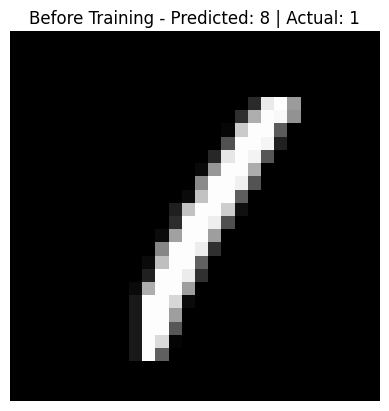

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8267 - loss: 0.6922 - val_accuracy: 0.9209 - val_loss: 0.2847
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9259 - loss: 0.2570 - val_accuracy: 0.9386 - val_loss: 0.2118
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9429 - loss: 0.1960 - val_accuracy: 0.9514 - val_loss: 0.1741
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9539 - loss: 0.1564 - val_accuracy: 0.9577 - val_loss: 0.1488
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9620 - loss: 0.1289 - val_accuracy: 0.9613 - val_loss: 0.1314
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9685 - loss: 0.1071 - val_accuracy: 0.9656 - val_loss: 0.1214
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9739 - loss: 0.0893 - val_accuracy: 0.9671 - val_loss: 0.1112
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9787 - loss: 0.0756 - val_accuracy:

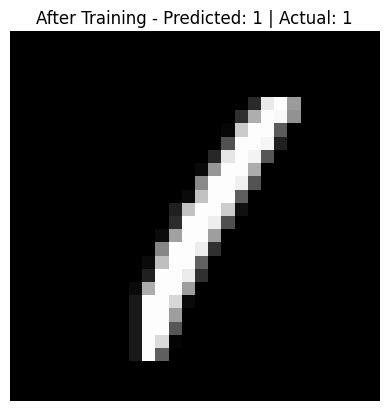


CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.96      0.98      0.97      1010
           4       0.97      0.97      0.97       982
           5       0.97      0.96      0.97       892
           6       0.99      0.96      0.98       958
           7       0.97      0.97      0.97      1028
           8       0.96      0.97      0.97       974
           9       0.97      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



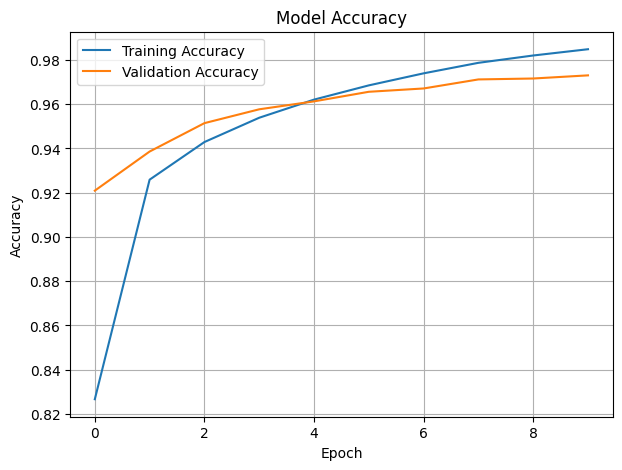

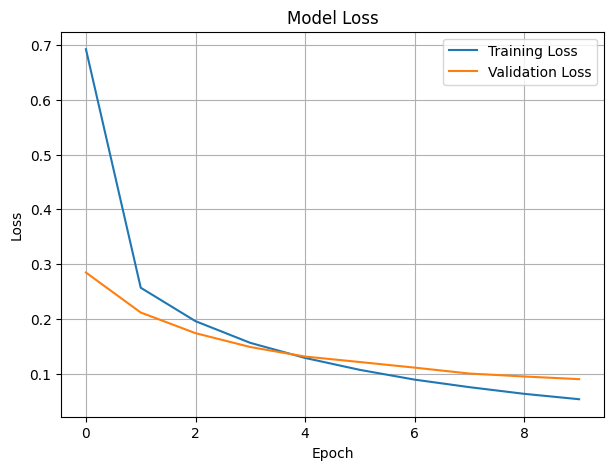

In [18]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

# Display sample image
plt.imshow(x_train[0], cmap="gray")
plt.title("Sample MNIST Image")
plt.axis("off")
plt.show()

print("Label:", y_train[0])

# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten images from 28x28 into 784
x_train = x_train.reshape(x_train.shape[0], 784)
x_test = x_test.reshape(x_test.shape[0], 784)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

# Convert labels into one-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

# Build neural network model
model = Sequential([
    Input(shape=(784,)),
    Dense(256, activation="sigmoid"),
    Dense(128, activation="sigmoid"),
    Dense(10, activation="softmax")
])

# Display model architecture
model.summary()

# Compile the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Evaluate before training
initial_loss, initial_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("\nBEFORE TRAINING")
print("----------------")
print("Loss:", initial_loss)
print("Accuracy:", initial_accuracy)

# Select a random test image
n = np.random.randint(0, len(x_test))

# Prediction before training
prediction_before = model.predict(
    x_test[n].reshape(1, 784), verbose=0
)

predicted_before = np.argmax(prediction_before)
actual_digit = np.argmax(y_test[n])

print("\nBEFORE TRAINING PREDICTION")
print("--------------------------")
print("Predicted Digit:", predicted_before)
print("Actual Digit:", actual_digit)

plt.imshow(x_test[n].reshape(28, 28), cmap="gray")
plt.title(
    "Before Training - Predicted: "
    + str(predicted_before)
    + " | Actual: "
    + str(actual_digit)
)
plt.axis("off")
plt.show()

# Train the model
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

# Evaluate after training
test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=0
)

print("\nAFTER TRAINING")
print("----------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# Prediction after training
prediction_after = model.predict(
    x_test[n].reshape(1, 784), verbose=0
)

predicted_after = np.argmax(prediction_after)
actual_digit = np.argmax(y_test[n])

print("\nAFTER TRAINING PREDICTION")
print("-------------------------")
print("Predicted Digit:", predicted_after)
print("Actual Digit:", actual_digit)

plt.imshow(x_test[n].reshape(28, 28), cmap="gray")
plt.title(
    "After Training - Predicted: "
    + str(predicted_after)
    + " | Actual: "
    + str(actual_digit)
)
plt.axis("off")
plt.show()

# Generate predictions for test data
predictions = model.predict(x_test, verbose=0)

predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(y_test, axis=1)

# Classification report
print("\nCLASSIFICATION REPORT")
print("---------------------")
print(
    classification_report(
        actual_classes,
        predicted_classes
    )
)

# Plot training and validation accuracy
plt.figure(figsize=(7, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.grid()
plt.show()

# Plot training and validation loss
plt.figure(figsize=(7, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.grid()
plt.show()